# 16 - Music Recommendation from Audio Features
**Topic:** Recommendation Systems  |  **Reference:** "Music Recommendation System using Spotify API" (amanxai.com, Jul 2023)

**Question.** Given a song, which other songs sound similar, and how would we know the list is any good when we have no listener data?

**Reference method:** get a Spotify developer token, download the audio features of some tracks through the API, and recommend by similarity of those numbers. (Spotify removed access to audio-feature data for new apps in November 2024 and the method needs personal credentials, so I use a public snapshot of **114,000 Spotify tracks with the same audio features** from the Hugging Face hub.)
**What I do:** clean the data (the same song appears many times), compare **ways of measuring "similar"** (raw numbers, standardised numbers, and a **learned embedding** from a small neural network trained to tell genres apart), and evaluate with measurable proxies on held-out songs: do the neighbours share a genre, how varied are the lists, and are a few songs recommended over and over ("hubs")?

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import stats
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
sns.set_theme(style="whitegrid", context="notebook")
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(8); os.makedirs("model", exist_ok=True)
raw = pd.read_csv("../_data/spotify/dataset.csv").drop(columns="Unnamed: 0")
print(raw.shape, "| distinct track ids:", raw.track_id.nunique(), "| distinct (title, artist) pairs:", raw.drop_duplicates(["track_name", "artists"]).shape[0], "| genres:", raw.track_genre.nunique()); raw.head(3).T

(114000, 20) | distinct track ids: 89741 | distinct (title, artist) pairs: 81344 | genres: 114


,0,1,2
track_id,5SuOikwiRyPMVoIQDJUgSV,4qPNDBW1i3p13qLCt0Ki3A,1iJBSr7s7jYXzM8EGcbK5b
artists,Gen Hoshino,Ben Woodward,Ingrid Michaelson;ZAYN
album_name,Comedy,Ghost (Acoustic),To Begin Again
track_name,Comedy,Ghost - Acoustic,To Begin Again
popularity,73,55,57
duration_ms,230666,149610,210826
explicit,False,False,False
danceability,0.676,0.42,0.438
energy,0.461,0.166,0.359
key,1,1,0


## 2. Clean: the same song appears many times
A track can be listed under several genres, and the same title/artist can exist as several releases (single, album, deluxe edition). If duplicates are left in, a song's own copy is its nearest neighbour, which would inflate every score. I merge rows with the same (title, artist) into **one** track that keeps its highest popularity and the **set of genres** it was listed under.

In [2]:
FEAT = ["danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]
raw = raw.dropna(subset=["track_name", "artists"] + FEAT)
raw = raw[(raw.tempo > 0) & (raw.duration_ms > 20000)]                        # drop silent / zero-tempo / very short items
g = raw.groupby(["track_name", "artists"])
df = g.agg({**{f: "median" for f in FEAT}, "popularity": "max", "track_id": "first", "album_name": "first", "explicit": "max"}).reset_index()
df["genres"] = g.track_genre.agg(lambda s: sorted(set(s))).values
df["n_genres"] = df.genres.str.len()
print("rows %d -> unique songs %d | songs listed under 2+ genres: %.1f%% | max genres for one song: %d" % (len(raw), len(df), (df.n_genres > 1).mean() * 100, df.n_genres.max()))

rows 113838 -> unique songs 81195 | songs listed under 2+ genres: 16.5% | max genres for one song: 9


## 3. Look at the data first

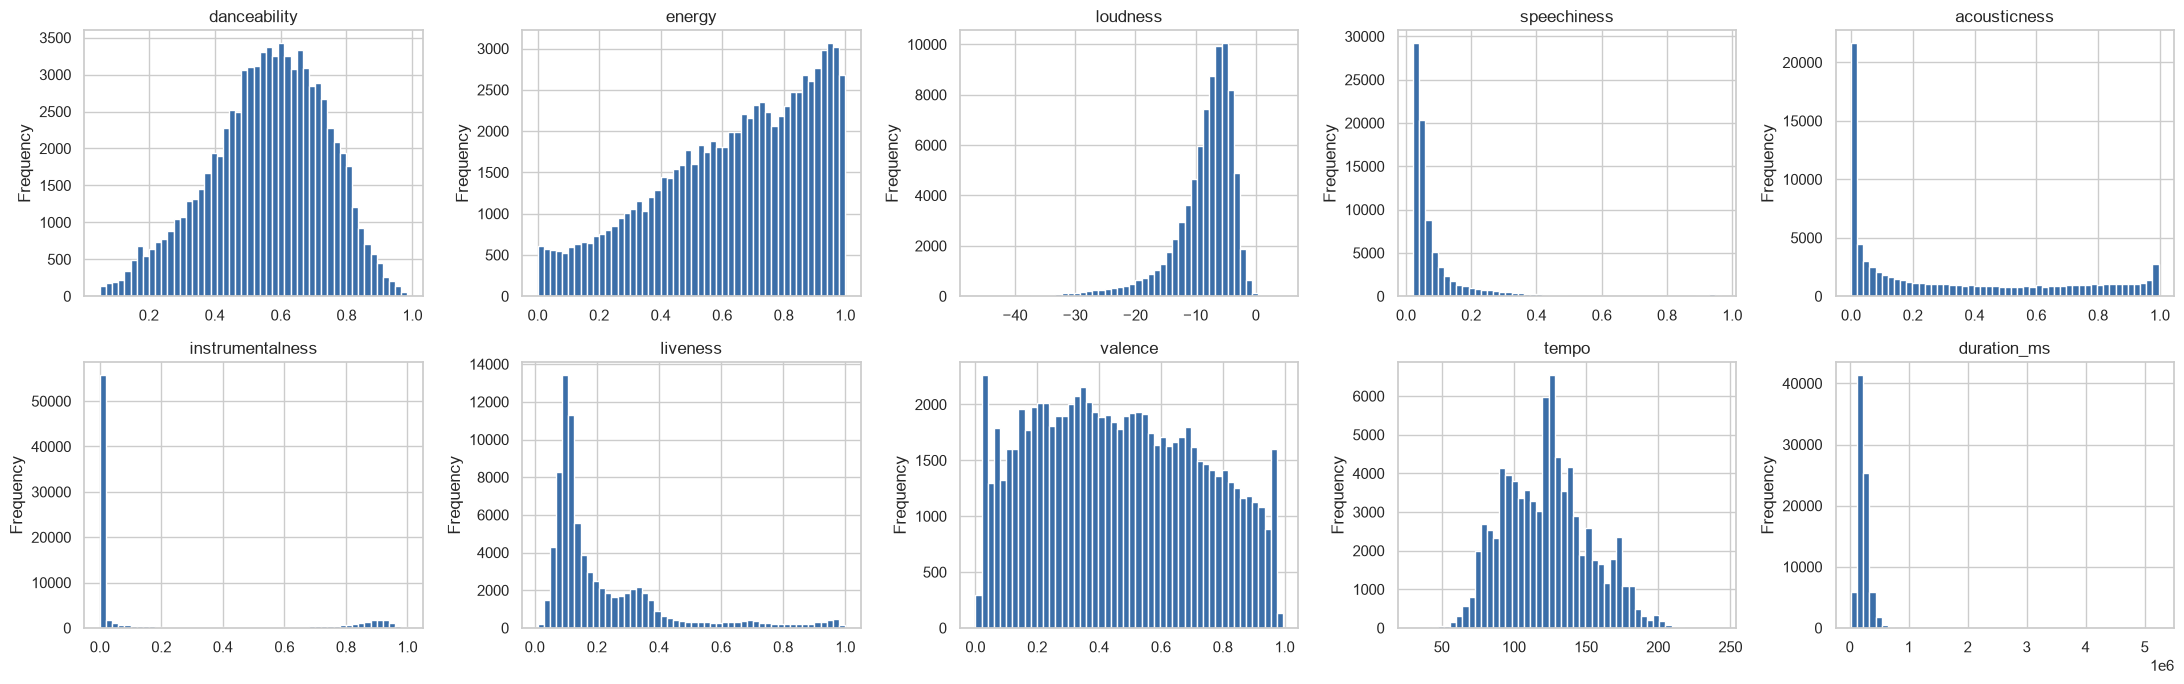

                       mean        std       min        50%         max
danceability           0.56       0.18      0.05       0.57        0.98
energy                 0.64       0.26      0.00       0.68        1.00
loudness              -8.57       5.26    -46.59      -7.26        4.53
speechiness            0.09       0.12      0.02       0.05        0.96
acousticness           0.33       0.34      0.00       0.19        1.00
instrumentalness       0.18       0.33      0.00       0.00        1.00
liveness               0.22       0.20      0.01       0.13        1.00
valence                0.46       0.26      0.00       0.45        1.00
tempo                122.36      29.67     30.20     122.05      243.37
duration_ms       231517.16  115211.70  21120.00  215295.00  5237295.00
popularity            35.25      19.42      0.00      35.00      100.00


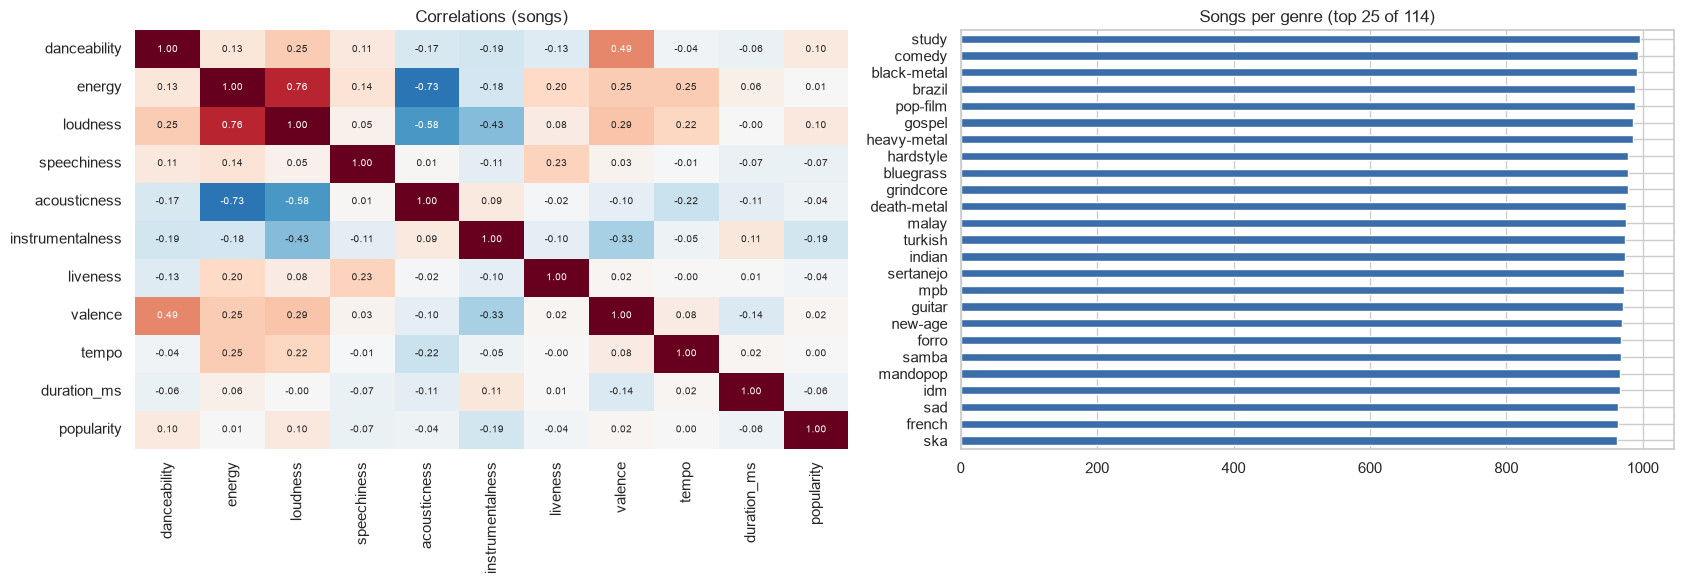

In [3]:
fig, ax = plt.subplots(2, 5, figsize=(22, 7))
for a, f in zip(ax.ravel(), FEAT): df[f].plot.hist(bins=50, ax=a, color="#3b6ea8"); a.set_title(f)
plt.tight_layout(); plt.show()
print(df[FEAT + ["popularity"]].describe().round(2).T[["mean", "std", "min", "50%", "max"]].to_string())
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(df[FEAT + ["popularity"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0], cbar=False, annot_kws={"size": 7}); ax[0].set_title("Correlations (songs)")
gen = pd.Series([x for l in df.genres for x in l]).value_counts(); gen.head(25).iloc[::-1].plot.barh(ax=ax[1], color="#3b6ea8"); ax[1].set_title("Songs per genre (top 25 of %d)" % len(gen))
plt.tight_layout(); plt.show()

**Reading it.**
* **Cleaning matters:** 113,838 usable rows collapse to **81,195 unique songs**; 16.5% of songs appear under 2 or more genres (one song under 9).
* The numeric features have very different scales: tempo 30-243 beats per minute (mean 122), loudness from -46.6 to +4.5 dB (mean -8.6), duration from 21 seconds to 87 minutes (mean 3.9 minutes, in *milliseconds* in the raw data), while danceability, energy, valence and the rest lie between 0 and 1. A distance on the raw numbers is therefore dominated by duration and tempo.
* Several features are very skewed: the median instrumentalness is 0 (most songs have vocals) and the median speechiness is 0.05.
* Popularity (0-100) averages 35. The data set holds roughly the same number of songs for each of its 114 genres, which makes genre counts look uniform; real catalogues are not like that.

## 4. Representations: what counts as "similar"?
For every song we need a vector; similar songs = nearby vectors (cosine similarity). Four options:
1. **Raw features** (as returned by the API: tempo in beats per minute, duration in milliseconds, loudness in dB, others between 0 and 1);
2. **Standardised** features (each column to mean 0, standard deviation 1);
3. **PCA-whitened** (standardised, rotated and rescaled so every direction counts equally);
4. **Learned embedding:** a small neural network (10 inputs -> 128 -> 64 -> one output per genre) is trained to predict the song's genres; its 64-number hidden layer is the embedding. It is trained on **80% of the songs only**.

In [4]:
tr, te = train_test_split(np.arange(len(df)), test_size=.2, random_state=0)
X = df[FEAT].to_numpy(float); sc = StandardScaler().fit(X[tr]); Xs = sc.transform(X)
pca = PCA(whiten=True, random_state=0).fit(Xs[tr]); Xp = pca.transform(Xs)
genres = sorted({x for l in df.genres for x in l}); gi = {g_: i for i, g_ in enumerate(genres)}
Y = np.zeros((len(df), len(genres)), np.float32)
for r_, l in enumerate(df.genres):
    for x in l: Y[r_, gi[x]] = 1
class Net(nn.Module):
    def __init__(self):
        super().__init__(); self.f = nn.Sequential(nn.Linear(10, 128), nn.ReLU(), nn.Dropout(.1), nn.Linear(128, 64), nn.ReLU()); self.h = nn.Linear(64, len(genres))
    def forward(self, x): e = self.f(x); return self.h(e), e
net = Net(); opt = torch.optim.Adam(net.parameters(), 2e-3, weight_decay=1e-5)
Xt, Yt = torch.tensor(Xs, dtype=torch.float32), torch.tensor(Y); tri = torch.tensor(tr)
for ep in range(25):
    net.train(); p = tri[torch.randperm(len(tri))]
    for k in range(0, len(p), 256):
        b = p[k:k + 256]; lo, _ = net(Xt[b]); loss = F.binary_cross_entropy_with_logits(lo, Yt[b]); opt.zero_grad(); loss.backward(); opt.step()
net.eval()
with torch.no_grad(): lo, Emb = net(Xt)
Emb = Emb.numpy()
top1 = np.array([Y[i, lo[i].argmax().item()] for i in te]); print("genre classifier: share of held-out songs whose top predicted genre is one of their listed genres: %.1f%% (a random genre would be right for about %.1f%%)" % (top1.mean() * 100, Y[te].sum(1).mean() / len(genres) * 100))

genre classifier: share of held-out songs whose top predicted genre is one of their listed genres: 24.2% (a random genre would be right for about 1.1%)


## 5. Evaluation without listeners: proxies, stated honestly
Queries are the **20% held-out songs**; the search database is the **80% training songs** (so the learned embedding has not seen the query). For each query we take the 10 most similar database songs and measure:
* **Genre precision@10:** the share of the 10 that share at least one genre with the query. Genre is only a proxy for taste: two songs of the same genre may be disliked together or apart.
* **Same-artist rate:** the share of recommendations by the query's own artist (a simple recommender can overdo this).
* **Diversity:** mean distance between the 10 recommended songs themselves (1 - cosine).
* **Hubness:** how unevenly songs are recommended. A song that appears in many lists is a *hub*; the share of database songs that never appear in any list, and how much of all recommendation slots go to the top 1% songs, measure it.

In [5]:
def l2(a): return a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-12)
reps = {"1 raw features": X, "2 standardised": Xs, "3 PCA-whitened": Xp, "4 learned embedding (genre net)": Emb}
art = df.artists.to_numpy(); G = Y.astype(bool)
def evaluate(V, k=10, q_idx=te, db_idx=tr, chunk=2000):
    Vn = l2(V); Q, D = Vn[q_idx], Vn[db_idx]; hits, same_art, div = [], [], []; occ = np.zeros(len(db_idx), int)
    for s in range(0, len(q_idx), chunk):
        S = Q[s:s + chunk] @ D.T; top = np.argpartition(-S, k, axis=1)[:, :k]
        for r_, row in enumerate(top):
            qi = q_idx[s + r_]; nb = db_idx[row]
            hits.append((G[nb] & G[qi]).any(1).mean()); same_art.append((art[nb] == art[qi]).mean()); occ[row] += 1
            M = D[row] @ D[row].T; div.append(1 - (M.sum() - k) / (k * (k - 1)))
    srt = np.sort(occ)[::-1]
    return {"genre_precision@10": np.mean(hits), "same_artist_rate": np.mean(same_art), "diversity": np.mean(div), "never_recommended_%": (occ == 0).mean() * 100, "top1%_songs_share_of_slots_%": srt[: int(.01 * len(occ))].sum() / occ.sum() * 100, "occurrence_skew": float(stats.skew(occ))}
t = time.time(); ev = pd.DataFrame({n: evaluate(v) for n, v in reps.items()}).T; print(ev.round(3).to_string()); print("evaluation time %.0fs" % (time.time() - t))

                                 genre_precision@10  same_artist_rate  diversity  never_recommended_%  top1%_songs_share_of_slots_%  occurrence_skew
1 raw features                                0.053             0.003      0.000               13.395                         3.570            0.873
2 standardised                                0.154             0.016      0.067               13.338                         3.628            0.915
3 PCA-whitened                                0.150             0.016      0.087               12.718                         3.657            0.923
4 learned embedding (genre net)               0.166             0.019      0.025               12.756                         3.595            0.892
evaluation time 84s


baseline: 10 RANDOM songs share a genre with the query in 1.2% of cases


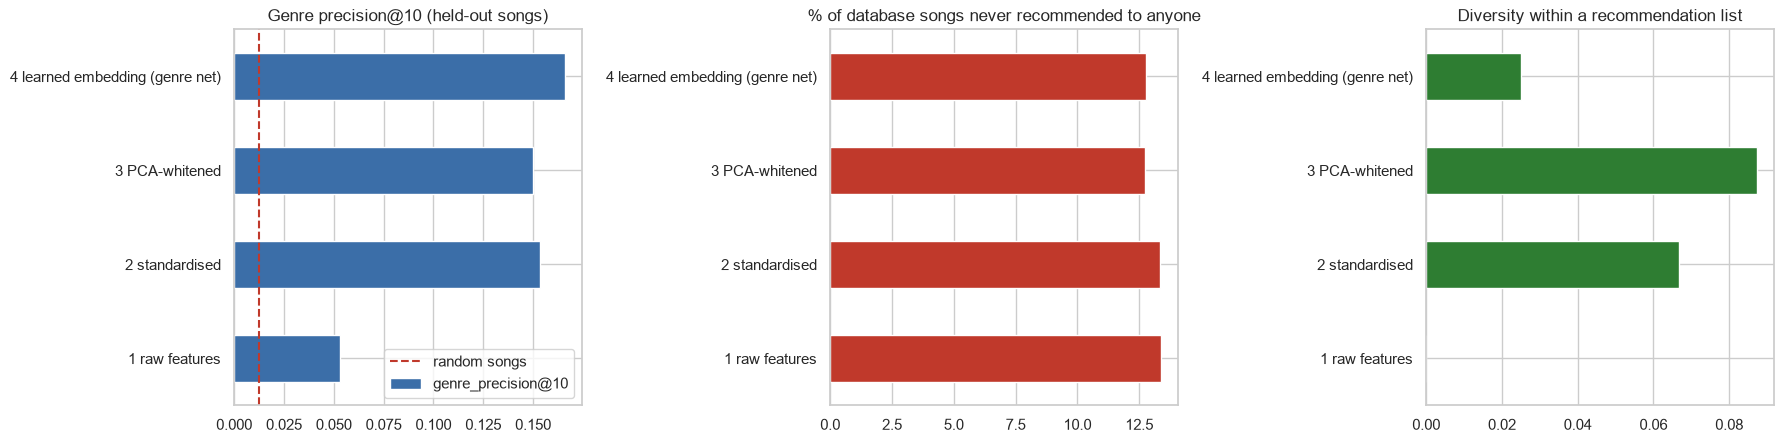

In [6]:
rng = np.random.RandomState(0); pop_idx = rng.choice(tr, 10, replace=True)
rand_prec = np.mean([(G[rng.choice(tr, 10)] & G[q]).any(1).mean() for q in te[:3000]])
print("baseline: 10 RANDOM songs share a genre with the query in %.1f%% of cases" % (rand_prec * 100))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ev["genre_precision@10"].plot.barh(ax=ax[0], color="#3b6ea8"); ax[0].axvline(rand_prec, color="#c0392b", ls="--", label="random songs"); ax[0].legend(); ax[0].set_title("Genre precision@10 (held-out songs)")
ev["never_recommended_%"].plot.barh(ax=ax[1], color="#c0392b"); ax[1].set_title("% of database songs never recommended to anyone")
ev["diversity"].plot.barh(ax=ax[2], color="#2e7d32"); ax[2].set_title("Diversity within a recommendation list")
plt.tight_layout(); plt.show()

**Reading it (held-out songs as queries; 10 recommendations each).**
* **Scaling is the single biggest effect:** with the raw numbers (as the API returns them) only **5.3%** of recommendations share a genre with the query, with standardised features **15.4%**, PCA-whitened 15.0% and the learned embedding **16.6%**. Random songs would match in 1.2% of cases. The raw version is nearly meaningless because duration in milliseconds swamps everything else (its "diversity" is 0.000: every vector points the same way, so cosine similarity is about 1 for every pair).
* The learned embedding is best, but only slightly above standardised features (16.6% vs 15.4%) and I have one split and no interval, so I would not claim it is reliably better.
* Even the best list is mostly *not* in the query's genre: about 83% of the recommendations are in other genres. Ten audio numbers are a thin description of a song: no lyrics, language, era, artist or listener behaviour.
* The genre-prediction network itself reaches 24.2% top-1 accuracy over 114 genres (about 1% by chance), which says the same thing from another side.
* Same-artist recommendations are rare (0.3%-1.9%), and about 13% of database songs are never recommended to anyone; the 1% most-recommended songs take only 3.6% of all slots, so there is mild "hubness" but no dominant hub. **Diversity values are not comparable across representations** (they depend on the geometry of each space), so I do not rank the methods by them.

## 6. Does popularity or explicitness leak into the recommendations?
A fair recommender should not always push the most popular songs. Mean popularity (0-100) of the recommended songs vs the database average, per representation.

In [7]:
def mean_pop(V, k=10):
    Vn = l2(V); Q, D = Vn[te[:4000]], Vn[tr]; S = Q @ D.T; top = np.argpartition(-S, k, axis=1)[:, :k]; return df.popularity.to_numpy()[tr][top].mean()
pp = {n: mean_pop(v) for n, v in reps.items()}; print("database mean popularity: %.1f | recommended (mean per list): %s" % (df.popularity.iloc[tr].mean(), {k: round(v, 1) for k, v in pp.items()}))

database mean popularity: 35.2 | recommended (mean per list): {'1 raw features': np.float64(35.8), '2 standardised': np.float64(34.9), '3 PCA-whitened': np.float64(35.0), '4 learned embedding (genre net)': np.float64(35.2)}


**Reading it.** The recommended songs are about as popular as the catalogue average (34.9-35.8 vs 35.2) for all four representations, so similarity on audio features does not drift toward hits (or away from them). That is a property of this feature set; adding listener data would bring popularity bias in.

## 7. A sanity check you can listen to

In [8]:
def find(title_part, artist_part=None):
    m = df.track_name.str.contains(title_part, case=False, regex=False) & ((df.artists.str.contains(artist_part, case=False, regex=False)) if artist_part else True)
    return df[m].sort_values("popularity", ascending=False).index[:1].tolist()
db_v = {"standardised": l2(Xs), "learned embedding": l2(Emb)}
seeds = [("Bohemian Rhapsody", "Queen"), ("Blinding Lights", "The Weeknd"), ("Clair de Lune", None), ("Lose Yourself", "Eminem")]
for t_, a_ in seeds:
    ix = find(t_, a_)
    if not ix: print("(not found:", t_, ")"); continue
    q = ix[0]; print("=" * 100); print("SEED:", df.track_name[q], "-", df.artists[q][:40], "|", ", ".join(df.genres[q][:3]))
    for nm, V in db_v.items():
        s = V @ V[q]; s[q] = -9; top = np.argsort(-s)[:5]; print(f"  {nm:18s}:", " | ".join(f"{df.track_name[j][:26]} ({df.artists[j][:16]}; {df.genres[j][0]})" for j in top))

SEED: Bohemian Rhapsody - Remastered 2011 - Queen | rock
  standardised      : Sevsen Ne Olurdu (Gülden Karaböcek; turkish) | Behold (Then Sings My Soul (Hillsong Worship; world-music) | Goodbye Milky Way (Enigma; new-age) | Le trou noir (Stupeflip;MC Sal; french) | Mere Yaar (The Local Train; indian)
  learned embedding : Na Unção de Deus (Elaine de Jesus; brazil) | Will o the Wisp (Opeth; death-metal) | Sevsen Ne Olurdu (Gülden Karaböcek; turkish) | Insomnia (IAMX; industrial) | The Blood (Bethel Music;Jen; ambient)
SEED: Blinding Lights - The Weeknd | pop
  standardised      : Quit (feat. Hudson Mohawke (Gammer;Hudson Mo; happy) | Part-Time Lover (Dabin;Claire Rid; dub) | Fire (Matrix & Futureb; drum-and-bass) | POP/STARS (K/DA;Madison Bee; k-pop) | Learn To Love Again (Audien; progressive-house)
  learned embedding : Changing (Sigma;Paloma Fai; drum-and-bass) | All Goes Wrong (Chase & Status;T; drum-and-bass) | It's All on U - T-Mass & L (ILLENIUM;Liam O'; dub) | Climbing The Walls

  learned embedding : Nocturne No. 19 in E Minor (Frédéric Chopin;; classical) | Suite bergamasque, L. 75:  (Claude Debussy;A; classical) | Gnossienne No. 1 (Erik Satie;Alena; classical) | Deux Arabesques, L66: No.  (Claude Debussy;K; classical) | Snow (Roger Eno;Brian ; ambient)
SEED: Lose Yourself - From "8 Mile" Soundtrack - Eminem | hip-hop
  standardised      : Drama Setter (Tony Yayo;Eminem; hardcore) | The Zero Hour (Wildstylez;Headh; hardstyle) | I Wanna Know (Dillinja; drum-and-bass) | I like It Loud (Hardcore M (The Prophet; happy) | Bring It Back - Tantrum De (Friction;Stylo G; drum-and-bass)
  learned embedding : I Wanna Know (Dillinja; drum-and-bass) | I like It Loud (Hardcore M (The Prophet; happy) | Drama Setter (Tony Yayo;Eminem; hardcore) | Back In The Days (Delete; hardstyle) | If We Ever - Unglued Remix (High Contrast;Un; drum-and-bass)


**Reading it.** The lists are a mixed bag, which is itself informative.
* **Classical works well:** for *Clair de Lune* both representations return Debussy, Chopin and Satie pieces (the nearest non-classical item is ambient piano).
* **Pop and rock do not:** *Bohemian Rhapsody* returns a Turkish pop song and devotional music; *Blinding Lights* returns drum-and-bass and dub tracks that match its energy and tempo but not its style; *Lose Yourself* returns hardcore and drum-and-bass tracks (plus one track that features Eminem, probably by luck).
* Audio features describe how a song *sounds* in 10 numbers (loudness, tempo, energy), not what it *is* (genre conventions, vocals, era). Hits from very different genres can have the same numbers. For a real product I would combine them with listener behaviour (collaborative filtering) and metadata (artist, language, era); 17 shows how to blend such signals.

## 8. Save: embedding model, scaler, song table

In [9]:
torch.save(net.state_dict(), "model/genre_embedding_net.pt"); joblib.dump({"scaler": sc, "features": FEAT, "genres": genres}, "model/scaler_genres.joblib")
keep = df[["track_name", "artists", "popularity", "n_genres"]].copy(); keep["genre"] = df.genres.str[0]; keep["genres"] = df.genres.str.join("|"); keep = pd.concat([keep, df[FEAT]], axis=1)
keep.to_csv("model/songs.csv.gz", index=False, compression="gzip"); np.save("model/embeddings.npy", l2(Emb).astype(np.float16))
json.dump({"n_songs": int(len(df)), "evaluation": ev.round(4).to_dict("index"), "random_genre_precision": float(rand_prec)}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['embeddings.npy', 'genre_embedding_net.pt', 'meta.json', 'scaler_genres.joblib', 'songs.csv.gz']


## 9. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | Spotify API (needs credentials; audio-feature access closed to new apps in Nov 2024) | public snapshot: 114,000 rows -> 81,195 unique songs, same audio features |
| Cleaning | none | duplicates merged (title + artist), genres kept as a set |
| Similarity | cosine on the API numbers | raw vs standardised vs PCA-whitened vs learned embedding |
| Evaluation | by listening | genre precision@10 on held-out songs: **raw 5.3% < whitened 15.0% < standardised 15.4% < learned 16.6%** (random 1.2%), coverage, hubness, popularity drift, listening check |

**What I learned.** (1) Putting features on a common scale mattered more than any model: raw numbers gave 5% vs 15% after standardising. (2) Duplicated songs would have made every score look better; they must be merged before evaluating. (3) Without user data we can only measure proxies; genre agreement is useful but is not "I would enjoy this". (4) Audio descriptors alone are weak for mainstream music but fine for distinctive acoustic styles (classical).

**Limits.** One random split of songs; genre is a crude proxy for taste; one embedding architecture, one seed; no listener data, lyrics or artist information; the data set has an artificial 1,000-songs-per-genre balance. **Next step:** evaluate with real playlists (does the recommended song co-occur in a playlist with the seed?) and blend with collaborative filtering.